# queuetruth quickstart: exact replay, shadow orders and the L2 model zoo

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sarptandoven/queuetruth/blob/main/examples/notebooks/01_quickstart.ipynb)

This notebook walks through the core loop of queuetruth on its **synthetic** dataset (2 instruments, 2 session
days, CME matching rules, generated by code). Nothing here is market data, so the numbers say nothing about any
real venue or simulator; they only show what each step produces.

1. Write the dataset and replay it exactly, checking the book invariants and trade parity.
2. Place *shadow orders* (hypothetical resting orders) into the real FIFO queue and see when they would fill.
3. Score a few L2 fill models (the "zoo") against that exact truth.
4. Explain one fill event by event, and step through the book interactively.

Every result is a Pydantic summary plus Parquet tables. `queuetruth.frames` turns both into pandas DataFrames
(or polars, with `backend="polars"`).

In [1]:
# Setup: on Colab (or anywhere queuetruth is missing) this installs it from PyPI; elsewhere it does nothing.
import importlib
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("queuetruth") is None:
    try:
        from IPython import get_ipython

        shell = get_ipython()
    except ImportError:
        shell = None
    if shell is not None:  # %pip lets Colab offer a restart when an already-imported package was upgraded
        shell.run_line_magic("pip", "install -q queuetruth pandas matplotlib")
    else:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "queuetruth", "pandas", "matplotlib"])
    importlib.invalidate_caches()
if importlib.util.find_spec("queuetruth") is None or importlib.util.find_spec("queuetruth.frames") is None:
    raise RuntimeError(
        "this notebook needs queuetruth.frames (first released after queuetruth 0.1.1): pip install -U queuetruth"
    )

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import queuetruth as qt
from queuetruth import frames

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (7.5, 3.4)})

WORK = Path("qt-notebooks") / "01_quickstart"
WORK.mkdir(parents=True, exist_ok=True)
print("queuetruth", qt.__version__, "| outputs under", WORK)

queuetruth 0.1.1 | outputs under qt-notebooks/01_quickstart


## 1. Write the synthetic dataset and replay it

`qt.fixtures_synth` writes the same dataset as `queuetruth fixtures synth`. `qt.replay` rebuilds every order book
from the order-level records; `parity` checks the replay's trades against the source's own trade prints, and the
eight invariant counters must all be zero on a clean tape.

In [3]:
DATA = WORK / "synth"
if not (DATA / "manifest.json").exists():
    qt.fixtures_synth(str(DATA))

replay = qt.replay({"dataset": {"path": str(DATA)}, "out": str(WORK / "replay"), "parity_trades": True})
bad = {k: v for k, v in replay.invariants.model_dump().items() if v}
print("records:", replay.stats.records, "| trades:", replay.stats.trades, "| instruments:", replay.stats.instruments)
print("invariant counters not zero:", bad or "none")
print("trade parity pass:", replay.parity.pass_)
print("data quality verdict:", replay.data_quality.verdict)

records: 199882 | trades: 16427 | instruments: 2
invariant counters not zero: none
trade parity pass: True
data quality verdict: clean


`frames.load_run` opens any run output directory: the summary document, the run id, and every table as a
DataFrame read on first access. `verify=True` re-checks each file against the sha256, size and row count the
summary recorded, so a modified or truncated output is caught before you analyse it.

In [4]:
run = frames.load_run(WORK / "replay", verify=True)
print(run)
bbo = run["bbo"]
bbo.head(3)

RunFrames(qt.replay_summary run_id=0a7685c6c721114c, 2 tables, backend=pandas: qt-notebooks/01_quickstart/replay)


,ts_event,instrument_id,sequence,bid_px,bid_sz,bid_ct,ask_px,ask_sz,ask_ct
0,2026-06-15 13:25:00+00:00,1,142660,4999750000000,3,1,5000250000000,13,2
1,2026-06-15 13:25:00.478481425+00:00,1,142661,4999750000000,6,2,5000250000000,13,2
2,2026-06-15 13:25:00.478508395+00:00,1,142662,5000000000000,6,1,5000250000000,13,2


## 2. Shadow orders in the real queue

A shadow is a hypothetical limit order placed at a sampled time and price. The exact engine inserts it at the back
of the real FIFO queue and follows every add, cancel and execution ahead of it, so its fill time is what really
would have happened (for an order too small to change anyone's behaviour). The default sample places 60% of orders
at the touch, 30% one or two ticks behind and 10% one tick inside (placement `1` below), of 1 lot or the median
order size. When the spread is one tick, an order one tick inside would cross the book, and the engine marks it
`rejected_would_cross` instead of filling it.

In [5]:
SHADOWS = WORK / "shadows.parquet"
sample = qt.sample_shadows({"dataset": {"path": str(DATA)}, "out": str(SHADOWS), "n": 1000, "seed": 0})
print(sample.n, "shadows | by placement (ticks from the touch):", sample.by_placement)

rs = qt.replay({"dataset": {"path": str(DATA)}, "out": str(WORK / "replay-shadows"), "shadows": {"path": str(SHADOWS)}})
sh = rs.shadows
print(f"filled {sh.n_filled}, partially filled only {sh.n_partial_only}, censored {sh.n_censored}, of {sh.n}")

results = frames.load_run(WORK / "replay-shadows")["shadow_results"]
results["end_state"].value_counts()

1000 shadows | by placement (ticks from the touch): {'0': 592, '-1': 190, '-2': 105, '1': 113}


filled 808, partially filled only 6, censored 12, of 1000


end_state
filled                  808
cancelled               103
rejected_would_cross     77
censored_clear           12
Name: count, dtype: int64

How long does a shadow wait? The time to first fill by how much displayed quantity was ahead of it when it went
live. Deeper in the queue means a longer wait, which is the effect every L2 queue model tries to approximate.

In [6]:
filled = results[results["ts_first_fill"].notna()].copy()
filled["wait_s"] = (filled["ts_first_fill"] - filled["ts_live"]).dt.total_seconds()
filled["queue_ahead"] = pd.qcut(filled["queue_ahead_at_live"].astype("float64"), 4, duplicates="drop")
filled.groupby("queue_ahead", observed=True)["wait_s"].describe()[["count", "25%", "50%", "75%"]].round(2)

,count,25%,50%,75%
queue_ahead,,,,
"(-0.001, 4.0]",206.0,7.81,21.65,41.54
"(4.0, 12.0]",205.0,13.14,30.54,68.75
"(12.0, 24.0]",211.0,15.66,35.58,84.89
"(24.0, 80.0]",192.0,17.40,37.98,99.44


## 3. The L2 model zoo against exact truth

`qt.run_zoo` replays the same shadows through L2 fill models (each sees only aggregated depth and trades, as a
backtester would) and through the exact engine. `fill_rate_bias` is the model's fill rate minus the exact fill
rate at each horizon, with a 95% block-bootstrap interval. `front_of_queue` and `trade_through_only` are the
optimistic and pessimistic bounds every real model should sit between. NautilusTrader's default touch model
(`nt_prob_touch` with `p = 1`) fills on any print at the order's price, which is exactly the optimistic bound, so
its row equals `front_of_queue`. All models are scored on the same shadows (printed above the table).

In [7]:
MODELS = ["hbt_power3[n=2]", "nt_prob_touch[p=1]", "nt_queue_l2", "front_of_queue", "trade_through_only"]
zoo = qt.run_zoo(
    {
        "dataset": {"path": str(DATA)},
        "shadows": {"path": str(SHADOWS)},
        "out": str(WORK / "zoo"),
        "models": MODELS,
        "bootstrap_b": 300,
    }
)
board = frames.leaderboard(zoo)
print(
    f"scored on {zoo.n_leaderboard} of {zoo.n_shadows} shadows (never-cancel shadows with an exact outcome; "
    f"{zoo.n_excluded_hbt_312} dropped because faithful hftbacktest aborted at its issue #312)"
)
board["horizon"] = board["horizon_ns"].map({10**8: "100ms", 10**9: "1s", 10**10: "10s", 6 * 10**10: "60s"})
board = board.dropna(subset=["horizon"])
board["model"] = board["model_id"].str.replace(r"\[.*mode=faithful.*?\]", "", regex=True)
pp = board.assign(bias_pp=100 * board["fill_rate_bias"])
pp.pivot(index="model", columns="horizon", values="bias_pp")[["100ms", "1s", "10s", "60s"]].round(2) + 0.0  # no -0.00

scored on 921 of 1000 shadows (never-cancel shadows with an exact outcome; 79 dropped because faithful hftbacktest aborted at its issue #312)


horizon,100ms,1s,10s,60s
model,,,,
front_of_queue,0.33,2.93,14.10,10.92
hbt_power3,0.00,0.00,0.03,-1.21
nt_prob_touch,0.33,2.93,14.10,10.92
nt_queue_l2,0.00,0.00,-0.30,-2.42
trade_through_only,-0.22,-0.65,-5.64,-14.87


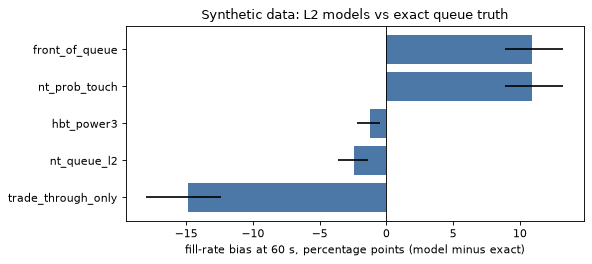

In [8]:
h60 = board[board["horizon"] == "60s"].sort_values("fill_rate_bias")
err = [100 * (h60["fill_rate_bias"] - h60["ci_lo"]), 100 * (h60["ci_hi"] - h60["fill_rate_bias"])]
fig, ax = plt.subplots()
ax.barh(h60["model"], 100 * h60["fill_rate_bias"], xerr=err, color="#4c78a8")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("fill-rate bias at 60 s, percentage points (model minus exact)")
ax.set_title("Synthetic data: L2 models vs exact queue truth")
fig.tight_layout()

The zoo's tables carry the per-shadow detail. `zoo_errors` holds every metric by stratum; here the bias of
NautilusTrader's default touch model by the decile of exact queue ahead at entry, which shows *where* a model is
wrong, not only by how much.

In [9]:
zrun = frames.load_run(WORK / "zoo")
errors = zrun["zoo_errors"]
nt = errors[
    errors["model_id"].str.startswith("nt_prob_touch")
    & (errors["metric"] == "fill_rate_bias")
    & (errors["horizon_ns"] == 10**10)
    & (errors["stratum_kind"] == "queue_decile")
]
cols = ["stratum", "value", "ci_lo", "ci_hi", "n"]
nt.assign(stratum=nt["stratum"].astype(int)).sort_values("stratum")[cols].round(3).reset_index(drop=True)

,stratum,value,ci_lo,ci_hi,n
0,0,0.000,0.000,0.000,58
1,1,0.096,0.052,0.154,104
2,2,0.194,0.105,0.281,62
3,3,0.194,0.138,0.260,103
4,4,0.203,0.122,0.283,74
5,5,0.161,0.103,0.218,93
6,6,0.235,0.142,0.332,85
7,7,0.143,0.092,0.203,91
8,8,0.133,0.071,0.194,83
9,9,0.148,0.082,0.213,88


## 4. Explain one fill, and query the book

`qt.why` replays one shadow and returns its queue timeline: every event at its price level, whether it was ahead
of the shadow, and how much queue was left ahead after it. `action` is the order-level record type: `A` add, `C`
cancel, `M` modify, `T` trade print, `F` fill of a resting order, `R` book clear.

In [10]:
# The first shadow submitted that had 8 to 20 lots ahead when it went live and filled 5 to 60 s later.
pick = filled[filled["queue_ahead_at_live"].between(8, 20) & filled["wait_s"].between(5, 60)]
sid = pick.sort_values(["ts_submit", "shadow_id"])["shadow_id"].iloc[0]
why = qt.why({"dataset": {"path": str(DATA)}, "shadows": {"path": str(SHADOWS)}, "shadow_id": sid})
print(f"shadow {sid}: {len(why.events)} events at its price level; outcome {why.outcome.end_state}")
trace = pd.DataFrame([e.model_dump() for e in why.events])
trace["ts_event"] = pd.to_datetime(trace["ts_event"], utc=True)
trace[["ts_event", "action", "effect", "is_ahead", "queue_ahead_after", "fill_qty"]]

shadow s2_20260615_000000: 12 events at its price level; outcome filled


,ts_event,action,effect,is_ahead,queue_ahead_after,fill_qty
0,2026-06-15 13:35:01.238466579+00:00,C,remove,True,7,0
1,2026-06-15 13:35:01.765576931+00:00,T,none,False,5,0
2,2026-06-15 13:35:01.765576931+00:00,F,none,True,5,0
3,2026-06-15 13:35:01.765576931+00:00,C,reduce,True,5,0
4,2026-06-15 13:35:06.291058303+00:00,T,none,False,4,0
5,2026-06-15 13:35:06.291058303+00:00,F,none,True,4,0
6,2026-06-15 13:35:06.291058303+00:00,C,reduce,True,4,0
7,2026-06-15 13:35:08.039627881+00:00,T,none,False,3,0
8,2026-06-15 13:35:08.039627881+00:00,F,none,True,3,0
9,2026-06-15 13:35:08.039627881+00:00,C,reduce,True,3,0


`qt.Session` steps through a dataset for point-in-time questions about the book.

In [11]:
inst = frames.read(DATA / "instruments.parquet").sort_values(["session_date", "instrument_id"]).iloc[0]
open_ns = int(inst["midnight_utc_ns"]) + int(inst["open_s"]) * 10**9
s = qt.Session(str(DATA))
s.advance_to(open_ns + 600 * 10**9)
bids, asks = s.depth(int(inst["instrument_id"]), 3)
scale = 10.0 ** int(inst["price_exp"])
print(f"{inst['symbol']} {inst['session_date']} 10 minutes after the open (price, qty, orders)")
print("bids:", [(round(p * scale, 2), q, c) for p, q, c in bids])
print("asks:", [(round(p * scale, 2), q, c) for p, q, c in asks])

QTAU6 2026-06-15 10 minutes after the open (price, qty, orders)
bids: [(5000.25, 13, 2), (5000.0, 16, 7), (4999.75, 48, 7)]
asks: [(5000.5, 6, 1), (5000.75, 32, 9), (5001.0, 65, 10)]


## Next

- [02: Is my NautilusTrader backtest too optimistic?](02_nautilus_too_optimistic.ipynb) runs the same comparison
  on real Nasdaq order-level data, and fixes the fill model.
- [03: Calibrate and export](03_calibrate_and_export.ipynb) fits a queue model's parameter against exact truth and
  exports it for hftbacktest or NautilusTrader, with a refusal when the fit does not beat the default.
- [04: Score your simulator against your fills](04_score_simulator_vs_fills.ipynb) compares a simulator with a
  live order log, order by order.